In [1]:
import matlab.engine

In [2]:
eng = matlab.engine.start_matlab()

In [3]:
s = eng.genpath("/home/kushal/repos/NMFLibrary/")
eng.addpath(s, nargout=0)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD Radeon Graphics (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 22.3.6
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (gfx1103_r1, LLVM 15.0.6, DRM 3.49, 6.1.0-28-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [5]:
%matplotlib inline

In [12]:
series, truth = generate_data(
    n_timepoints=1_000,
    n_components=3,
    noise=5,
    n_pixels=5,
    n_pixels_bg=0,
    firing_prop=0.05
)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='500px', css_width='700px')
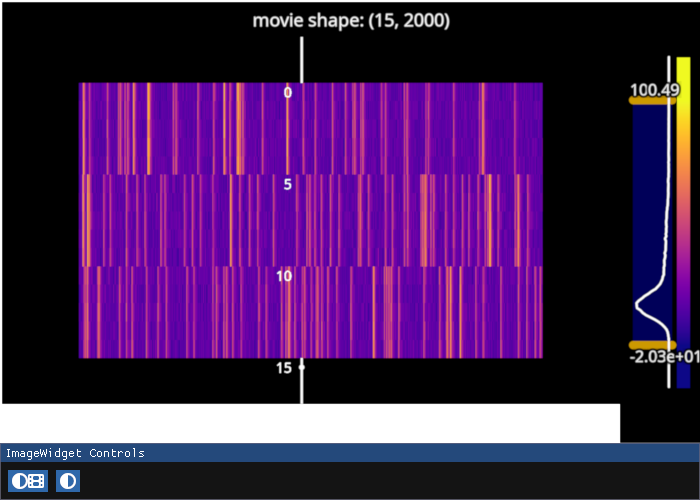

In [13]:
iw_series = fpl.ImageWidget(
    series, 
    figure_kwargs={"size": (700, 500)},
    names=[f"movie shape: {series.shape}"],
)
iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.show()

In [14]:
series.shape

(15, 2000)

In [15]:
overlap1 = series[:5] + series[5:10]
overlap2 = series[5:10] + series[10:15]

In [16]:
series = np.vstack([series, overlap1, overlap2])

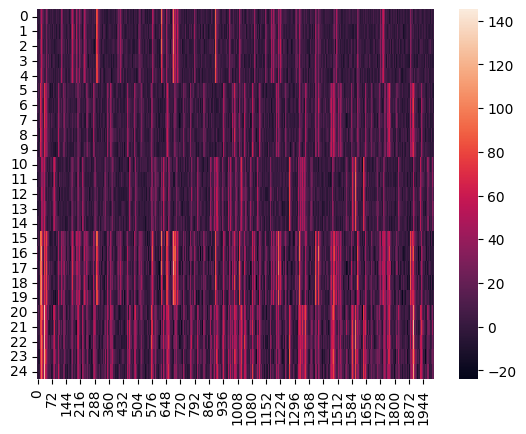

In [17]:
sns.heatmap(series)
plt.show()

In [18]:
Y = series

In [19]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [20]:
@njit(parallel=True)
def get_distances(
    i: int,
    Y: np.ndarray,
    projections: np.ndarray,
    dists: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]

        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v

        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        v1 = Vt[0, :]

        projections_pre = (X @ v1)
        
        projections[j, :u.size, 0] = projections_pre * v1[0]
        projections[j, :u.size, 1] = projections_pre * v1[1]

        orthogonal_distances = np.abs(X - projections[j, :u.size])  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)

        dists[j] = s

In [21]:
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))

In [22]:
get_distances(
    0,
    Y,
    projections,
    output_matrix,
)

/tmp/ipykernel_2749/1061025827.py:24: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'C', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  projections_pre = (X @ v1)
/tmp/ipykernel_2749/1061025827.py:24: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'C', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  projections_pre = (X @ v1)


In [23]:
output_matrix.shape

(25,)

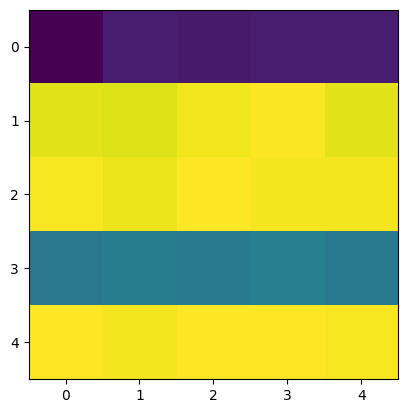

In [25]:
plt.imshow(output_matrix.reshape(5, 5))

In [26]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [27]:
for i in range(Y.shape[0]):
    projections = np.zeros((*Y.shape, 2))
    output_matrix = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        projections,
        output_matrix,
    )
    dist_cov[i] = output_matrix

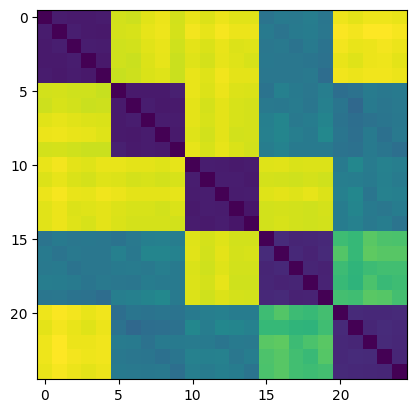

In [28]:
plt.imshow(dist_cov)

In [115]:
from ipywidgets import VBox, HBox

In [136]:
lam = 1e1

A = np.exp(-dist_cov**2 / lam**2)

W = np.asarray(eng.symm_anls(A, 3.0)["W"])

iw_matrices = fpl.ImageWidget([dist_cov, A], names=["D: Distance matrix", "Affinity, e^(-D^2 / λ^2)"], cmap="viridis")
iw_snmf = fpl.ImageWidget(W, names=["W: Cluster memberships"], cmap="viridis", histogram_widget=False)

vals, edges = np.histogram(dist_cov.ravel(), bins=100)
cdf = np.column_stack([edges[1:], np.cumsum(vals[::-1])])

fig_cdf = fpl.Figure(names=[["cdf(D)"]])
cdf_g = fig_cdf[0, 0].add_line(cdf)

cdf_selector = cdf_g.add_linear_selector()
cdf_selector.selection = lam

fig_scatter = fpl.Figure(cameras="3d", controller_types="orbit", names=[["W: cluster memberships"]])

n = 5
colors = list()
for c in "rgbyc":
    colors += [c] * n

W_scatter_g = fig_scatter[0, 0].add_scatter(W, sizes=10, colors=colors, alpha=0.6)

fig_scatter.show()

@cdf_selector.add_event_handler("selection")
def update_lam(ev):
    lam = ev.graphic.selection

    A = np.exp(-dist_cov**2 / lam**2)
    iw_matrices.managed_graphics[1].data = A
    W = np.asarray(eng.symm_anls(A, 3.0)["W"])
    iw_snmf.set_data(W, reset_vmin_vmax=True)

    W_scatter_g.data[:] = W

HBox([
    VBox([iw_matrices.show(), fig_cdf.show(maintain_aspect=False)]),
    HBox([iw_snmf.show(), fig_scatter.show()])
])

RFBOutputContext()

RFBOutputContext()

RFBOutputContext()

RFBOutputContext()

In [125]:
cdf_selector.selection = 1e2

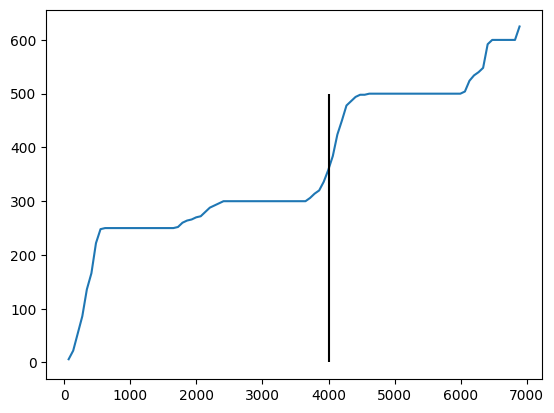

In [35]:
plt.plot(edges[1:], np.cumsum(vals[::-1]))
plt.vlines(4e3, ymin=0, ymax=500, color="k")

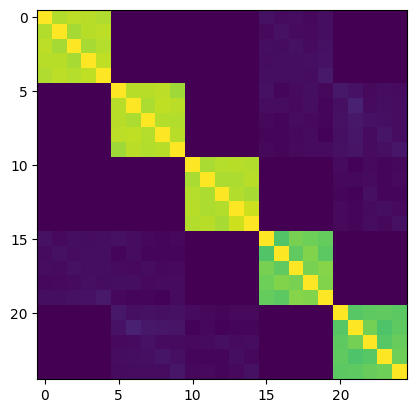

In [108]:
A = np.exp(-dist_cov**2 / 1.5e3**2)
plt.imshow(A)

In [109]:
results = eng.symm_anls(A, 3.0)

In [110]:
W = np.asarray(results["W"])

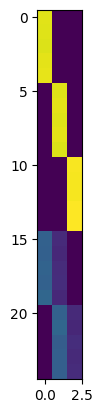

In [111]:
plt.imshow(W)

In [112]:
n = 5
colors = list()
for c in "rgbyc":
    colors += [c] * n

RFBOutputContext()

JupyterWgpuCanvas()
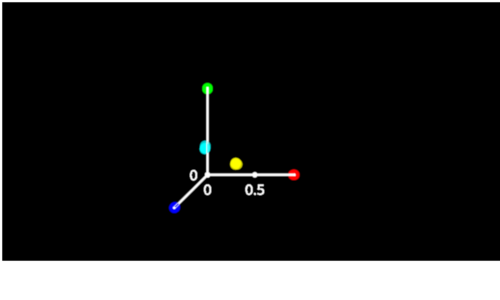

In [113]:
fig = fpl.Figure(cameras="3d", controller_types="orbit")

fig[0, 0].add_scatter(W, sizes=10, colors=colors, alpha=0.6)

fig.show()